In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

BASE_PATH = Path(
    r"D:\Capstone\metal additive manufacturing"
)

DATASET_PATH = BASE_PATH / "data" / "Original Images and Manual Labels" / "Original Images and manual labels"

OUTPUT_PATH = BASE_PATH / "EDA" / "outputs"

print("Dataset exists:", DATASET_PATH.exists())
print("Output folder exists:", OUTPUT_PATH.exists())
print("Output files:")

for file in sorted(OUTPUT_PATH.glob("*")):
    print(file.name)

Dataset exists: True
Output folder exists: True
Output files:
.ipynb_checkpoints
ot_annotations_parsed.csv
ot_defect_class_counts.csv
ot_defects_per_image.csv
ot_exact_duplicates.csv
ot_filename_metadata.csv
ot_image_quality.csv
ot_intensity_statistics.csv
ot_invalid_bounding_boxes.csv
pb_annotations.csv
pb_filename_metadata.csv
pb_image_quality.csv
pb_intensity_statistics.csv
pb_ot_build_counts.csv
pb_ot_exact_filename_matches.csv


In [2]:
pb_filename_df = pd.read_csv(OUTPUT_PATH / "pb_filename_metadata.csv")
ot_filename_df = pd.read_csv(OUTPUT_PATH / "ot_filename_metadata.csv")
build_counts = pd.read_csv(OUTPUT_PATH / "pb_ot_build_counts.csv")
alignment_df = pd.read_csv(OUTPUT_PATH / "pb_ot_exact_filename_matches.csv")

print("PB filename metadata:", pb_filename_df.shape)
print("OT filename metadata:", ot_filename_df.shape)
print("Build counts:", build_counts.shape)
print("Exact filename matches:", alignment_df.shape)

display(build_counts)
display(alignment_df.head())

PB filename metadata: (2638, 4)
OT filename metadata: (2674, 7)
Build counts: (3, 4)
Exact filename matches: (0, 5)


,Unnamed: 0,PB_image_count,OT_image_count,difference_OT_minus_PB
0,SI383820240318120348,1367,1383,16
1,SI383820211201123521,1000,1005,5
2,SI383820240226095904,271,286,15


,image_stem,pb_image_exists,ot_image_exists,pb_xml_exists,ot_xml_exists


In [3]:
print("ALL FILES IN EDA OUTPUTS\n")

for file in sorted(OUTPUT_PATH.iterdir()):
    if file.is_file():
        print(f"{file.name}  |  {file.stat().st_size / 1024:.2f} KB")

ALL FILES IN EDA OUTPUTS

ot_annotations_parsed.csv  |  662.07 KB
ot_defect_class_counts.csv  |  0.03 KB
ot_defects_per_image.csv  |  52.99 KB
ot_exact_duplicates.csv  |  0.40 KB
ot_filename_metadata.csv  |  227.44 KB
ot_image_quality.csv  |  194.21 KB
ot_intensity_statistics.csv  |  228.64 KB
ot_invalid_bounding_boxes.csv  |  0.13 KB
pb_annotations.csv  |  649.62 KB
pb_filename_metadata.csv  |  270.51 KB
pb_image_quality.csv  |  221.58 KB
pb_intensity_statistics.csv  |  267.82 KB
pb_ot_build_counts.csv  |  0.15 KB
pb_ot_exact_filename_matches.csv  |  0.07 KB


In [4]:
# Load all exported EDA results

pb_annotations = pd.read_csv(OUTPUT_PATH / "pb_annotations.csv")
ot_annotations = pd.read_csv(OUTPUT_PATH / "ot_annotations_parsed.csv")

pb_quality = pd.read_csv(OUTPUT_PATH / "pb_image_quality.csv")
ot_quality = pd.read_csv(OUTPUT_PATH / "ot_image_quality.csv")

pb_intensity = pd.read_csv(OUTPUT_PATH / "pb_intensity_statistics.csv")
ot_intensity = pd.read_csv(OUTPUT_PATH / "ot_intensity_statistics.csv")

ot_class_counts = pd.read_csv(OUTPUT_PATH / "ot_defect_class_counts.csv")
ot_defects_per_image = pd.read_csv(OUTPUT_PATH / "ot_defects_per_image.csv")

ot_duplicates = pd.read_csv(OUTPUT_PATH / "ot_exact_duplicates.csv")
ot_invalid_boxes = pd.read_csv(OUTPUT_PATH / "ot_invalid_bounding_boxes.csv")

# Inspect column names and sample rows

datasets = {
    "PB annotations": pb_annotations,
    "OT annotations": ot_annotations,
    "PB image quality": pb_quality,
    "OT image quality": ot_quality,
    "PB intensity": pb_intensity,
    "OT intensity": ot_intensity,
    "OT defect classes": ot_class_counts,
    "OT defects per image": ot_defects_per_image,
    "OT duplicates": ot_duplicates,
    "OT invalid boxes": ot_invalid_boxes
}

for name, df in datasets.items():
    print(f"\n{'='*55}")
    print(name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.head(2))


PB annotations
Shape: (5001, 7)
Columns: ['filename', 'label_file', 'class', 'xmin', 'ymin', 'xmax', 'ymax']


,filename,label_file,class,xmin,ymin,xmax,ymax
0,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,276,725,350,738
1,SI383820211201123521_00009_20211201T125928.564...,SI383820211201123521_00009_20211201T125928.564...,defects,586,745,656,761



OT annotations
Shape: (4339, 14)
Columns: ['xml_filename', 'image_filename', 'width', 'height', 'class_name', 'xmin', 'ymin', 'xmax', 'ymax', 'bbox_width', 'bbox_height', 'bbox_area', 'bbox_center_x', 'bbox_center_y']


,xml_filename,image_filename,width,height,class_name,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area,bbox_center_x,bbox_center_y
0,SI383820211201123521_113_003_920_Int_32F.xml,SI383820211201123521_113_003_920_Int_32F.jpg,2000,2000,overheated,391,1159,447,1210,56,51,2856,419.0,1184.5
1,SI383820211201123521_145_005_200_Int_32F.xml,SI383820211201123521_145_005_200_Int_32F.jpg,2000,2000,overheated,341,1548,385,1597,44,49,2156,363.0,1572.5



PB image quality
Shape: (2638, 6)
Columns: ['filename', 'width', 'height', 'mode', 'file_size_kb', 'valid']


,filename,width,height,mode,file_size_kb,valid
0,SI383820211201123521_00009_20211201T125928.564...,1280,1024,L,122.532227,True
1,SI383820211201123521_00010_20211201T125941.618...,1280,1024,L,120.929688,True


... (10 outputs left out)


OT duplicates
Shape: (5, 2)
Columns: ['filename', 'hash']


,filename,hash
0,SI383820240318120348_1258_026_180_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f
1,SI383820240318120348_1269_026_400_Int_32F.jpg,345d03806cc04b7fca992c089a4b6f9f



OT invalid boxes
Shape: (0, 14)
Columns: ['xml_filename', 'image_filename', 'width', 'height', 'class_name', 'xmin', 'ymin', 'xmax', 'ymax', 'bbox_width', 'bbox_height', 'bbox_area', 'bbox_center_x', 'bbox_center_y']


,xml_filename,image_filename,width,height,class_name,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area,bbox_center_x,bbox_center_y


In [5]:
# PB annotation statistics
pb_annotated_images = pb_annotations["filename"].nunique()
pb_total_boxes = len(pb_annotations)
pb_unannotated_images = len(pb_quality) - pb_annotated_images

# OT annotation statistics
ot_annotated_images = ot_annotations["image_filename"].nunique()
ot_total_boxes = len(ot_annotations)
ot_unannotated_images = len(ot_quality) - ot_annotated_images

# Image validity
pb_valid = pb_quality["valid"].sum()
ot_valid = ot_quality["valid"].sum()

# Image intensity averages
pb_mean_intensity = pb_intensity["mean_intensity"].mean()
ot_mean_intensity = ot_intensity["mean_intensity"].mean()

# Bounding box statistics
pb_avg_box_area = (
    (pb_annotations["xmax"] - pb_annotations["xmin"]) *
    (pb_annotations["ymax"] - pb_annotations["ymin"])
).mean()

ot_avg_box_area = ot_annotations["bbox_area"].mean()

# Print summary
summary = pd.DataFrame({
    "Metric": [
        "Total images",
        "Valid images",
        "Annotated images",
        "Images without annotations",
        "Total bounding boxes",
        "Average boxes per annotated image",
        "Average image intensity",
        "Average bounding box area"
    ],
    "PB": [
        len(pb_quality),
        pb_valid,
        pb_annotated_images,
        pb_unannotated_images,
        pb_total_boxes,
        pb_total_boxes / pb_annotated_images,
        pb_mean_intensity,
        pb_avg_box_area
    ],
    "OT": [
        len(ot_quality),
        ot_valid,
        ot_annotated_images,
        ot_unannotated_images,
        ot_total_boxes,
        ot_total_boxes / ot_annotated_images,
        ot_mean_intensity,
        ot_avg_box_area
    ]
})

display(summary.round(2))

,Metric,PB,OT
0,Total images,2638.00,2674.00
1,Valid images,2638.00,2674.00
2,Annotated images,1530.00,1122.00
3,Images without annotations,1108.00,1552.00
4,Total bounding boxes,5001.00,4339.00
5,Average boxes per annotated image,3.27,3.87
6,Average image intensity,130.25,66.02
7,Average bounding box area,20644.79,23885.41


In [6]:
# PB: attach image dimensions to each annotation
pb_box_analysis = pb_annotations.merge(
    pb_quality[["filename", "width", "height"]],
    on="filename",
    how="left"
)

pb_box_analysis["bbox_area"] = (
    (pb_box_analysis["xmax"] - pb_box_analysis["xmin"]) *
    (pb_box_analysis["ymax"] - pb_box_analysis["ymin"])
)

pb_box_analysis["normalized_area_pct"] = (
    pb_box_analysis["bbox_area"] /
    (pb_box_analysis["width"] * pb_box_analysis["height"])
) * 100


# OT: calculate normalized bounding-box area
ot_box_analysis = ot_annotations.copy()

ot_box_analysis["normalized_area_pct"] = (
    ot_box_analysis["bbox_area"] /
    (ot_box_analysis["width"] * ot_box_analysis["height"])
) * 100


# Compare both modalities
normalized_comparison = pd.DataFrame({
    "Metric": [
        "Average normalized box area (%)",
        "Median normalized box area (%)",
        "Minimum normalized box area (%)",
        "Maximum normalized box area (%)"
    ],
    "PB": [
        pb_box_analysis["normalized_area_pct"].mean(),
        pb_box_analysis["normalized_area_pct"].median(),
        pb_box_analysis["normalized_area_pct"].min(),
        pb_box_analysis["normalized_area_pct"].max()
    ],
    "OT": [
        ot_box_analysis["normalized_area_pct"].mean(),
        ot_box_analysis["normalized_area_pct"].median(),
        ot_box_analysis["normalized_area_pct"].min(),
        ot_box_analysis["normalized_area_pct"].max()
    ]
})

display(normalized_comparison.round(5))

,Metric,PB,OT
0,Average normalized box area (%),1.57507,0.59714
1,Median normalized box area (%),0.62996,0.17272
2,Minimum normalized box area (%),0.00000,0.00060
3,Maximum normalized box area (%),6.41312,1.91055


In [7]:
# Check PB bounding boxes
pb_box_analysis["bbox_width"] = (
    pb_box_analysis["xmax"] - pb_box_analysis["xmin"]
)

pb_box_analysis["bbox_height"] = (
    pb_box_analysis["ymax"] - pb_box_analysis["ymin"]
)

pb_zero_boxes = pb_box_analysis[
    (pb_box_analysis["bbox_width"] <= 0) |
    (pb_box_analysis["bbox_height"] <= 0)
]

pb_invalid_boxes = pb_box_analysis[
    (pb_box_analysis["xmin"] < 0) |
    (pb_box_analysis["ymin"] < 0) |
    (pb_box_analysis["xmax"] > pb_box_analysis["width"]) |
    (pb_box_analysis["ymax"] > pb_box_analysis["height"]) |
    (pb_box_analysis["bbox_width"] <= 0) |
    (pb_box_analysis["bbox_height"] <= 0)
]

print("PB zero-area bounding boxes:", len(pb_zero_boxes))
print("PB invalid bounding boxes:", len(pb_invalid_boxes))

display(pb_zero_boxes.head(10))

PB zero-area bounding boxes: 1
PB invalid bounding boxes: 1


,filename,label_file,class,xmin,ymin,xmax,ymax,width,height,bbox_area,normalized_area_pct,bbox_width,bbox_height
149,SI383820211201123521_00087_20211201T142533.828...,SI383820211201123521_00087_20211201T142533.828...,defects,670,674,670,675,1280,1024,0,0.0,0,1


In [8]:
pb_invalid_boxes.to_csv(
    OUTPUT_PATH / "pb_invalid_bounding_boxes.csv",
    index=False
)

print("PB invalid bounding-box report saved.")

PB invalid bounding-box report saved.


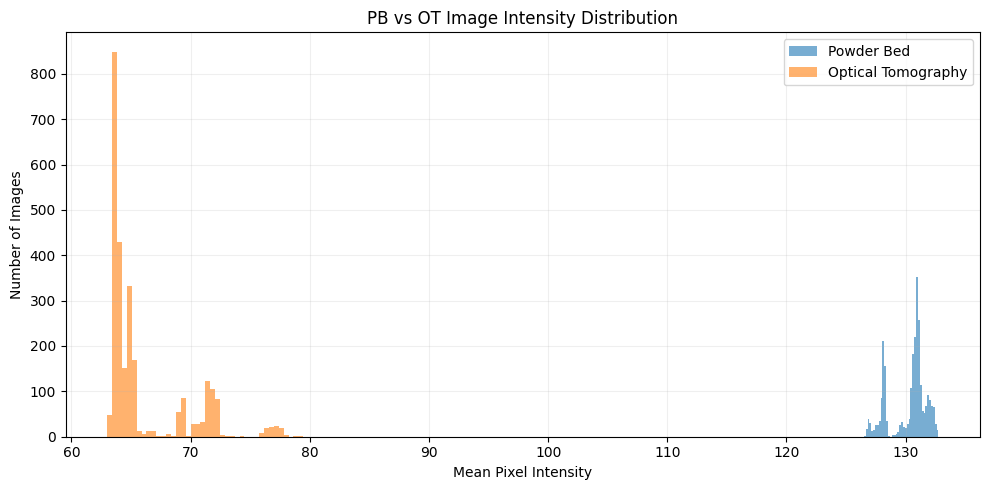

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(
    pb_intensity["mean_intensity"],
    bins=40,
    alpha=0.6,
    label="Powder Bed"
)

plt.hist(
    ot_intensity["mean_intensity"],
    bins=40,
    alpha=0.6,
    label="Optical Tomography"
)

plt.xlabel("Mean Pixel Intensity")
plt.ylabel("Number of Images")
plt.title("PB vs OT Image Intensity Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

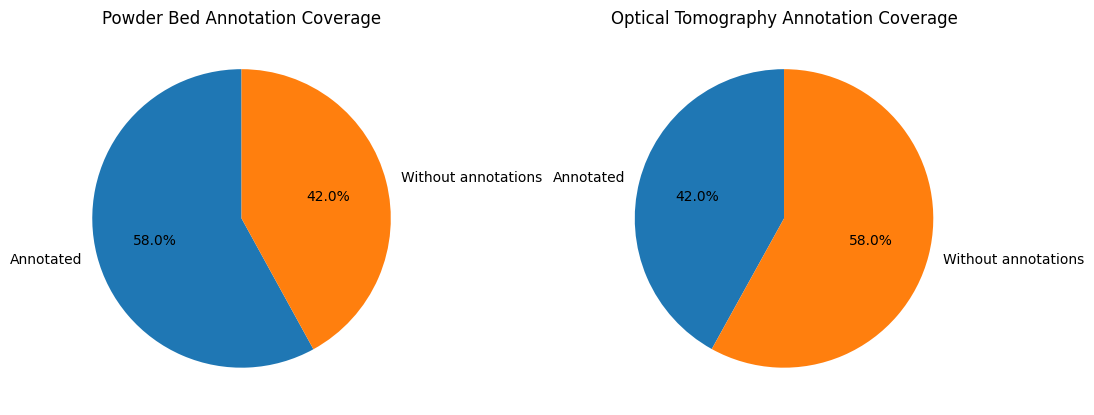

In [10]:
# Annotation coverage comparison

pb_annotated = pb_annotations["filename"].nunique()
ot_annotated = ot_annotations["image_filename"].nunique()

pb_unannotated = len(pb_quality) - pb_annotated
ot_unannotated = len(ot_quality) - ot_annotated

labels = ["Annotated", "Without annotations"]

pb_values = [pb_annotated, pb_unannotated]
ot_values = [ot_annotated, ot_unannotated]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].pie(
    pb_values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Powder Bed Annotation Coverage")

axes[1].pie(
    ot_values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Optical Tomography Annotation Coverage")

plt.tight_layout()
plt.show()

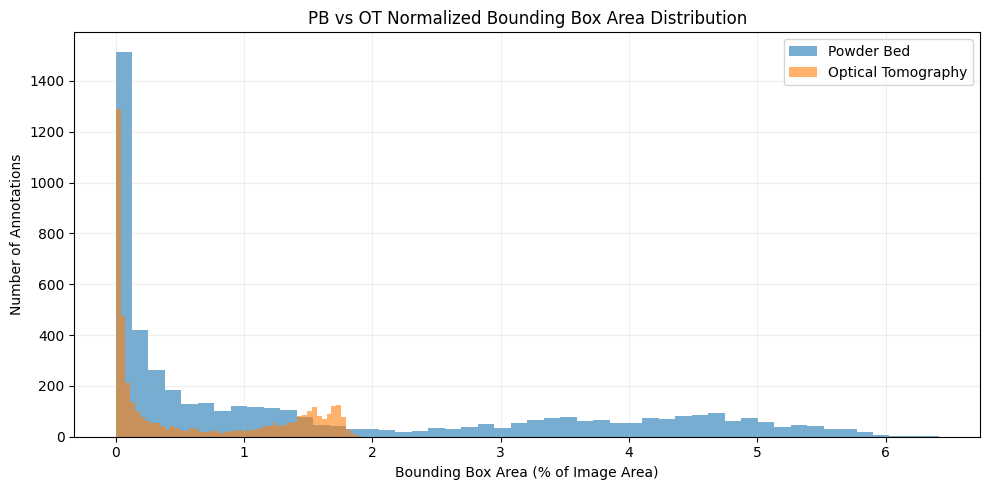

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(
    pb_box_analysis["normalized_area_pct"],
    bins=50,
    alpha=0.6,
    label="Powder Bed"
)

plt.hist(
    ot_box_analysis["normalized_area_pct"],
    bins=50,
    alpha=0.6,
    label="Optical Tomography"
)

plt.xlabel("Bounding Box Area (% of Image Area)")
plt.ylabel("Number of Annotations")
plt.title("PB vs OT Normalized Bounding Box Area Distribution")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

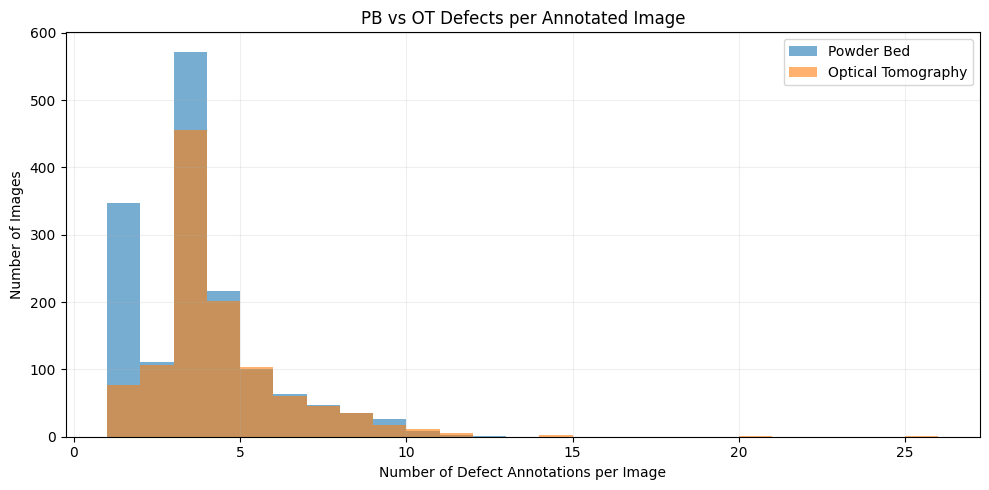

In [12]:
# Count PB bounding boxes per annotated image
pb_defects_per_image = (
    pb_annotations.groupby("filename")
    .size()
)

# OT already has defects-per-image data
ot_defects_counts = ot_defects_per_image["defect_count"]

plt.figure(figsize=(10, 5))

plt.hist(
    pb_defects_per_image,
    bins=range(1, int(pb_defects_per_image.max()) + 2),
    alpha=0.6,
    label="Powder Bed"
)

plt.hist(
    ot_defects_counts,
    bins=range(1, int(ot_defects_counts.max()) + 2),
    alpha=0.6,
    label="Optical Tomography"
)

plt.xlabel("Number of Defect Annotations per Image")
plt.ylabel("Number of Images")
plt.title("PB vs OT Defects per Annotated Image")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

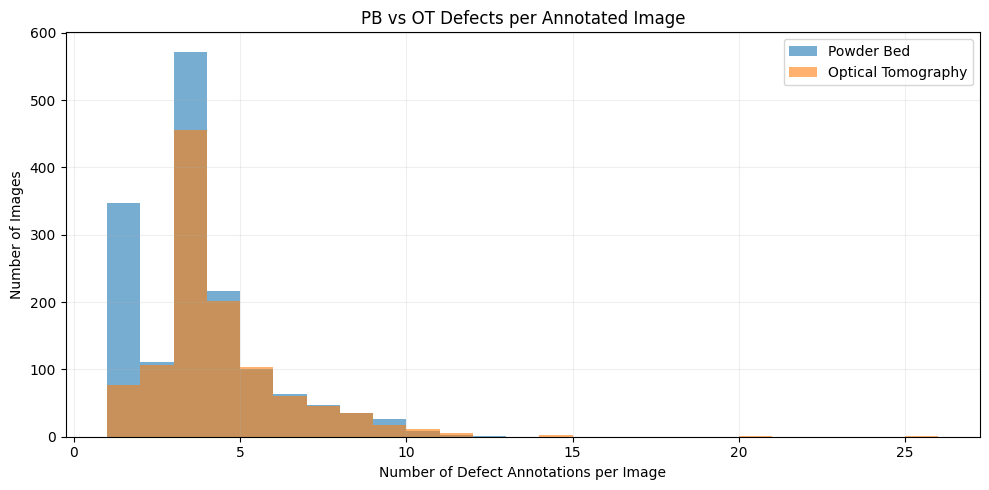

Consolidated EDA results saved successfully.


In [13]:
# Save consolidated summary tables

summary.to_csv(
    OUTPUT_PATH / "pb_ot_consolidated_summary.csv",
    index=False
)

normalized_comparison.to_csv(
    OUTPUT_PATH / "pb_ot_normalized_bbox_comparison.csv",
    index=False
)

pb_box_analysis.to_csv(
    OUTPUT_PATH / "pb_bbox_analysis.csv",
    index=False
)

ot_box_analysis.to_csv(
    OUTPUT_PATH / "ot_bbox_analysis.csv",
    index=False
)

# Save defects-per-image statistics
pb_defects_per_image.rename("defect_count").to_csv(
    OUTPUT_PATH / "pb_defects_per_image.csv"
)

# Save final plot
plt.figure(figsize=(10, 5))

plt.hist(pb_defects_per_image, bins=range(
    1, int(pb_defects_per_image.max()) + 2
), alpha=0.6, label="Powder Bed")

plt.hist(ot_defects_counts, bins=range(
    1, int(ot_defects_counts.max()) + 2
), alpha=0.6, label="Optical Tomography")

plt.xlabel("Number of Defect Annotations per Image")
plt.ylabel("Number of Images")
plt.title("PB vs OT Defects per Annotated Image")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "pb_ot_defects_per_image.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Consolidated EDA results saved successfully.")

## Dataset Reference and Validation

**Reference:** Yin, X., Akmal, J. S., Salmi, M., and Björkstrand, R. (2025). *Annotated Image Dataset for defects detection in Laser Powder Bed Fusion*. Zenodo. DOI: 10.5281/zenodo.14996805.

### Official dataset characteristics

- Manufacturing process: Laser-based Powder Bed Fusion (PBF-LB).
- Machine: EOS M290.
- Material: 316L stainless steel.
- Powder Bed images: 2,638 images at 1280 × 1024 resolution.
- Optical Tomography images: 2,674 images at 2000 × 2000 resolution.
- Annotations: Manually labeled XML files created using LabelImg.

### Validation against our EDA

The PB and OT image counts and image dimensions match the official dataset description.

Our inspection additionally identified:
- 5,001 PB bounding boxes.
- 4,339 OT bounding boxes.
- 1,530 PB XML annotation files.
- 1,124 OT XML annotation files.
- One invalid PB bounding box.
- Zero invalid OT bounding boxes.
- Five OT image entries in the exact-duplicate report.

These additional statistics were obtained through our own inspection and are not presented as official counts from the dataset record.

### Reference

https://zenodo.org/records/14996806